# Predicting Telecom Customer Churn

This notebook compares Random Forest and XGBoost classifiers to predict which telecom customers are likely to leave. About 26.5% of customers in this dataset churned. We compare weighted and unweighted settings for each classifier using five-fold stratified cross-validation and select the settings with the highest mean validation ROC-AUC.

Our goal is a ROC-AUC above 0.80 on held-out customers. We compare the models’ ROC curves, use confusion matrices to examine missed churners and false alarms, and identify the ten most important features for each model.

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

RANDOM_STATE = 42

In [19]:
churn = pd.read_csv("Telco_Customer_Churn.csv")
print(churn.shape)
churn.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
churn.info()

print("\nDuplicate customer IDs:", churn["customerID"].duplicated().sum())
print("\nChurn counts:")
print(churn["Churn"].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [21]:
churn["TotalCharges"] = pd.to_numeric(churn["TotalCharges"], errors="coerce")

print("TotalCharges data type:", churn["TotalCharges"].dtype)
print("Missing total charges:", churn["TotalCharges"].isna().sum())

TotalCharges data type: float64
Missing total charges: 11


In [22]:
X = churn.drop(columns=["customerID", "Churn"])
y = churn["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Training set: {len(X_train):,} customers, {y_train.mean():.1%} churn")
print(f"Test set: {len(X_test):,} customers, {y_test.mean():.1%} churn")
print(f"Predictor columns: {X_train.shape[1]}")

Training set: 5,634 customers, 26.5% churn
Test set: 1,409 customers, 26.5% churn
Predictor columns: 19


In [23]:
missing_charges = X_train["TotalCharges"].isna()

print(f"Training customers with missing total charges: {missing_charges.sum()}")
display(X_train.loc[missing_charges, ["tenure", "MonthlyCharges", "TotalCharges"]])

Training customers with missing total charges: 8


,tenure,MonthlyCharges,TotalCharges
6670,0,73.35,NaN
4380,0,20.00,NaN
3826,0,25.35,NaN
488,0,52.55,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
6754,0,61.90,NaN
3331,0,19.85,NaN


All eight training records with missing TotalCharges have zero months of tenure. We retain these customers and flag the missing charge with a separate indicator. During cross-validation, we fill missing charges using the median from each training fold. The indicator lets both models distinguish an imputed charge from a recorded one.

In [24]:
categorical_columns = X_train.select_dtypes(include=["object", "string"]).columns

for column in categorical_columns:
    print(f"{column}: {X_train[column].value_counts(dropna=False).to_dict()}")

print(f"SeniorCitizen: {X_train['SeniorCitizen'].value_counts(dropna=False).to_dict()}")

gender: {'Male': 2833, 'Female': 2801}
Partner: {'No': 2905, 'Yes': 2729}
Dependents: {'No': 3955, 'Yes': 1679}
PhoneService: {'Yes': 5075, 'No': 559}
MultipleLines: {'No': 2685, 'Yes': 2390, 'No phone service': 559}
InternetService: {'Fiber optic': 2483, 'DSL': 1937, 'No': 1214}
OnlineSecurity: {'No': 2797, 'Yes': 1623, 'No internet service': 1214}
OnlineBackup: {'No': 2442, 'Yes': 1978, 'No internet service': 1214}
DeviceProtection: {'No': 2472, 'Yes': 1948, 'No internet service': 1214}
TechSupport: {'No': 2771, 'Yes': 1649, 'No internet service': 1214}
StreamingTV: {'No': 2226, 'Yes': 2194, 'No internet service': 1214}
StreamingMovies: {'No': 2217, 'Yes': 2203, 'No internet service': 1214}
Contract: {'Month-to-month': 3102, 'Two year': 1359, 'One year': 1173}
PaperlessBilling: {'Yes': 3331, 'No': 2303}
PaymentMethod: {'Electronic check': 1891, 'Mailed check': 1286, 'Bank transfer (automatic)': 1244, 'Credit card (automatic)': 1213}
SeniorCitizen: {0: 4714, 1: 920}


## Preprocess the predictors

In [25]:
numeric_columns = X_train.select_dtypes(include="number").columns

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ]
)

print(f"Numeric predictors: {len(numeric_columns)}")
print(f"Categorical predictors: {len(categorical_columns)}")

Numeric predictors: 4
Categorical predictors: 15


## Tune the Random Forest classifier

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

forest_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
])

forest_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid={
        "model__class_weight": [None, "balanced"],
        "model__min_samples_leaf": [1, 5, 10],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
)

In [27]:
forest_search.fit(X_train, y_train)

print("Best settings:", forest_search.best_params_)
print(f"Best mean validation ROC-AUC: {forest_search.best_score_:.4f}")

Best settings: {'model__class_weight': None, 'model__min_samples_leaf': 10}
Best mean validation ROC-AUC: 0.8473


## Tune the XGBoost classifier

In [28]:
churn_weight = y_train.value_counts()[0] / y_train.value_counts()[1]

xgb_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid={
        "model__scale_pos_weight": [1.0, churn_weight],
        "model__max_depth": [2, 3, 4],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
)

print(f"Churn class weight to test: {churn_weight:.2f}")

Churn class weight to test: 2.77


In [29]:
xgb_search.fit(X_train, y_train)

print("Best settings:", xgb_search.best_params_)
print(f"Best mean validation ROC-AUC: {xgb_search.best_score_:.4f}")

Best settings: {'model__max_depth': 2, 'model__scale_pos_weight': 1.0}
Best mean validation ROC-AUC: 0.8498


## Comparing weighted and unweighted models

In [30]:
comparison_rows = []

for name, search in [("Random Forest", forest_search), ("XGBoost", xgb_search)]:
    for params, mean_auc, std_auc in zip(
        search.cv_results_["params"],
        search.cv_results_["mean_test_score"],
        search.cv_results_["std_test_score"],
    ):
        if name == "Random Forest":
            weight = params["model__class_weight"]
            weighting = "Equal" if weight is None else "Balanced"
            setting = f"min_samples_leaf={params['model__min_samples_leaf']}"
        else:
            weight = params["model__scale_pos_weight"]
            weighting = "Equal" if weight == 1.0 else f"Churn weight ×{weight:.2f}"
            setting = f"max_depth={params['model__max_depth']}"

        comparison_rows.append({
            "Model": name,
            "Weighting": weighting,
            "Tree setting": setting,
            "Mean validation ROC-AUC": mean_auc,
            "Fold standard deviation": std_auc,
        })

comparison = pd.DataFrame(comparison_rows)
best_rows = comparison.groupby(["Model", "Weighting"])["Mean validation ROC-AUC"].idxmax()
display(comparison.loc[best_rows].reset_index(drop=True).round(4))

,Model,Weighting,Tree setting,Mean validation ROC-AUC,Fold standard deviation
0,Random Forest,Balanced,min_samples_leaf=10,0.8467,0.0091
1,Random Forest,Equal,min_samples_leaf=10,0.8473,0.0094
2,XGBoost,Churn weight ×2.77,max_depth=2,0.8492,0.0121
3,XGBoost,Equal,max_depth=2,0.8498,0.0117


For both classifiers, equal class weights gave a mean validation ROC-AUC about 0.0006 higher than the weighted alternative. We therefore used equal class weights for the held-out test evaluation.

## Held-out test results

In [31]:
models = {
    "Random Forest": forest_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}

test_probabilities = {}

for name, model in models.items():
    churn_probability = model.predict_proba(X_test)[:, 1]
    test_probabilities[name] = churn_probability
    test_auc = roc_auc_score(y_test, churn_probability)
    print(f"{name} test ROC-AUC: {test_auc:.4f}")

Random Forest test ROC-AUC: 0.8438
XGBoost test ROC-AUC: 0.8453


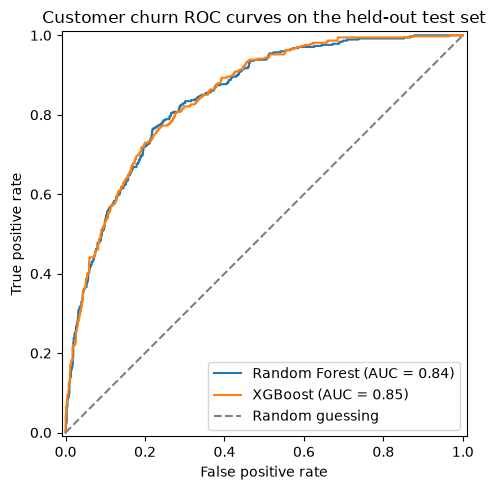

In [32]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
ax.set_title("Customer churn ROC curves on the held-out test set")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")

fig.tight_layout()
plt.show()


## Confusion matrices at a 0.50 threshold

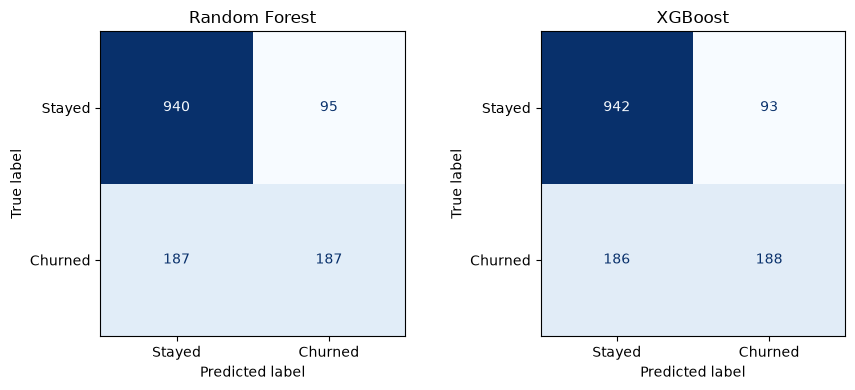

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (name, probabilities) in zip(axes, test_probabilities.items()):
    predicted_churn = (probabilities >= 0.50).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted_churn,
        labels=[0, 1],
        display_labels=["Stayed", "Churned"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax,
    )
    ax.set_title(name)

fig.tight_layout()
plt.show()

At the 0.50 threshold, Random Forest detected 187 of 374 actual churners (50.0% recall), and 187 of the 282 customers it flagged actually churned (66.3% precision). XGBoost detected 188 of 374 churners (50.3% recall), and 188 of its 281 flagged customers actually churned (66.9% precision). In practical terms, both models caught about half of the customers who left, and about two in three churn alerts were correct.

## Top 10 features for predicting churn

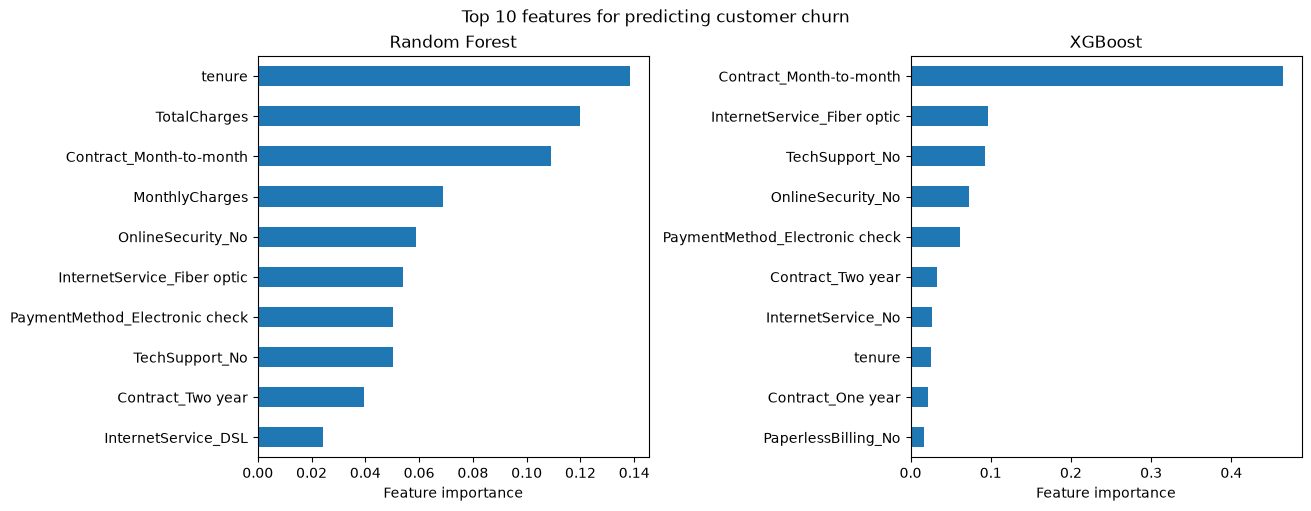

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

for ax, (name, pipeline) in zip(axes, models.items()):
    feature_names = pipeline.named_steps["preprocess"].get_feature_names_out()
    importances = pipeline.named_steps["model"].feature_importances_

    top_features = pd.Series(importances, index=feature_names).nlargest(10)
    top_features = top_features.sort_values()
    top_features.index = top_features.index.str.replace(
        r"^(numeric|categorical)__", "", regex=True
    )

    top_features.plot.barh(ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Feature importance")
    ax.set_ylabel("")

fig.suptitle("Top 10 features for predicting customer churn")
plt.show()

## Conclusion

Both models exceeded the ROC-AUC target of 0.80 on the 1,409 held-out customers. XGBoost scored 0.8453 and Random Forest scored 0.8438. At the 0.50 classification threshold, XGBoost detected 188 of the 374 customers who churned and raised 93 false alarms. Random Forest detected 187 and raised 95 false alarms. Both models therefore missed about half of the customers who churned at this threshold.

Tenure and total charges ranked highest for Random Forest. The month-to-month contract indicator ranked first for XGBoost and third for Random Forest, making it a prominent predictor in both models. These rankings describe how the fitted models used the features. Establishing why customers leave would require further evidence.